# 07 — Estacionariedade: teste ADF em cada série

Passo 5 do roteiro de EDA (`docs/02_roteiro_eda.md`): teste de Dickey-Fuller aumentado (ADF) em cada série do painel — **obrigatório antes de qualquer regressão ou causalidade de Granger**, porque séries com tendência podem parecer relacionadas só por "subirem juntas" (regressão espúria, risco já levantado no `06_correlacao.ipynb`).

**Pergunta do notebook:** quais séries são estacionárias no nível, e quais precisam de primeira diferença (Δ) para chegar lá?

**Escolhas metodológicas** (registradas aqui para o relatório):

- **Recorte:** `painel_credito` (2015-01 a 2025-09, 129 meses), o mesmo do `06`, para que todas as séries cubram exatamente o mesmo período.
- **Especificação do ADF:** com constante (`regression='c'`), sem tendência determinística; número de defasagens escolhido automaticamente por AIC (`autolag='AIC'`). 
AIC (Akaike Information Criterion) é uma nota que ajuda a escolher entre modelos. Ele premia o modelo que se ajusta bem aos dados, mas desconta pontos por complexidade. Quanto menor o AIC, melhor.
- **Regra de decisão:** a série é considerada estacionária se o **p-valor < 0,05** (equivalente a estatística ADF mais negativa que o valor crítico de 5%). Hipótese nula do teste: *existe raiz unitária* (não estacionária).

In [2]:
%pip install statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.stattools import adfuller

painel = pd.read_csv('https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(painel['ano'].astype(str) + '-' + painel['mes'].astype(str) + '-01')

# recorte decidido no 05_tratamento_nans.ipynb: 2015-01 a 2025-09, sem NaN nas colunas ESTBAN
painel_credito = painel[painel['data'] <= '2025-09-01'].copy()

series = ['cambio_venda', 'credito_total', 'exportação_fob', 'importação_fob', 'exportação_kg', 'importação_kg']
dados = painel_credito.set_index('data')[series]
print(f"painel_credito: {len(dados)} meses, NaNs restantes: {dados.isna().sum().sum()}")

def fmt(x, casas=2):
    """Número no formato brasileiro (vírgula decimal)."""
    return f"{x:.{casas}f}".replace('.', ',')

def tabela_md(df):
    """DataFrame de strings -> tabela Markdown."""
    cab = '| ' + ' | '.join(['série'] + list(df.columns)) + ' |'
    sep = '|' + '---|' * (len(df.columns) + 1)
    linhas = ['| ' + ' | '.join([f'`{idx}`'] + [str(v) for v in row]) + ' |' for idx, row in df.iterrows()]
    return '\n'.join([cab, sep] + linhas)

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/11.3 MB 10.4 MB/s eta 0:00:01
   -------- ------------------------------- 2.4/11.3 MB 5.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 6.9 MB/s eta 0:00:02
   --------------- ------------------------ 4.5/11.3 MB 6.4 MB/s eta 0:00:02
   ---------------- ----------------------- 4.7/11.3 MB 4.9 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 4.4 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 4.5 MB/s eta 0:00:02
   -------------------------------------- - 11.0/11.3 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 6.7 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ----- ---------------------------------- 5.2/37.4 MB 33.6 MB/s eta 0:00:01
   ---------- ----------------------------- 9.4/37.4 MB 22.5 MB/s eta 0:00:02
   --------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


painel_credito: 129 meses, NaNs restantes: 0


## 1. O ADF "por dentro", na mão, para o `cambio_venda`

Antes de rodar o teste pronto, vale ver que ele é uma **regressão linear seguida de uma divisão**:

$$\Delta y_t = a + \gamma \, y_{t-1} + \varepsilon_t$$

- `Δy` = quanto a série mudou no mês; `y_{t-1}` = onde ela estava no mês anterior.
- Se **γ = 0**: o nível anterior não influencia a mudança seguinte, ou seja, não há "puxão de volta" (raiz unitária, passeio aleatório).
- Se **γ < 0**: quanto mais alta a série está, mais negativa tende a ser a próxima mudança (há puxão de volta, série estacionária).
- A **estatística ADF** é simplesmente `γ / erro padrão de γ`.

A célula abaixo faz essa regressão só com NumPy (sem defasagens extras) e compara com o `adfuller` do statsmodels configurado da mesma forma (`maxlag=0`, `autolag=None`).

In [3]:
y = dados['cambio_venda'].to_numpy()
dy = np.diff(y)        # Δy_t: quanto mudou de um mês pro outro
y_ant = y[:-1]         # y_{t-1}: onde estava no mês anterior

X = np.column_stack([np.ones(len(y_ant)), y_ant])          # colunas: constante e y_{t-1}
coef, *_ = np.linalg.lstsq(X, dy, rcond=None)              # mínimos quadrados
residuos = dy - X @ coef
s2 = residuos @ residuos / (len(dy) - X.shape[1])          # variância do erro
erro_padrao = np.sqrt(s2 * np.diag(np.linalg.inv(X.T @ X)))

gama, ep_gama = coef[1], erro_padrao[1]
t_manual = gama / ep_gama

stat_sm, p_sm, *_ = adfuller(y, maxlag=0, regression='c', autolag=None)

print(f"γ (coeficiente de y_(t-1)) : {gama:.4f}")
print(f"erro padrão de γ           : {ep_gama:.4f}")
print(f"estatística ADF na mão     : {t_manual:.4f}")
print(f"estatística ADF statsmodels: {stat_sm:.4f}   (p-valor {p_sm:.4f})")
print(f"diferença entre os dois    : {abs(t_manual - stat_sm):.2e}")

γ (coeficiente de y_(t-1)) : -0.0318
erro padrão de γ           : 0.0179
estatística ADF na mão     : -1.7796
estatística ADF statsmodels: -1.7796   (p-valor 0.3907)
diferença entre os dois    : 1.71e-14


C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3818749067.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat_sm, p_sm, *_ = adfuller(y, maxlag=0, regression='c', autolag=None)


Os dois valores coincidem: o que o `adfuller` devolve é exatamente esse `γ / erro padrão`. O **p-valor** vem de comparar essa estatística com a distribuição de Dickey-Fuller (não com a normal/t comum, porque sob a hipótese nula a série é um passeio aleatório e a distribuição da estatística é outra, com cauda negativa mais pesada).

Daqui em diante usamos o `adfuller` completo, com defasagens escolhidas por AIC — a versão "aumentada", que acrescenta termos `Δy_{t-1}, Δy_{t-2}, ...` à regressão para absorver autocorrelação (importante nas séries de comércio exterior, que têm sazonalidade mensal).

## 2. ADF no nível (séries brutas)

In [4]:
def roda_adf(serie, autolag='AIC'):
    stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(), regression='c', autolag=autolag)
    return {'stat': stat, 'p': p, 'defas': defas, 'nobs': nobs, 'crit5': crit['5%'], 'ok': p < 0.05}

def tabela_adf(resultados):
    df = pd.DataFrame(resultados).T
    saida = pd.DataFrame({
        'estatística ADF': df['stat'].map(fmt),
        'crítico 5%': df['crit5'].map(fmt),
        'p-valor': df['p'].map(lambda v: fmt(v, 4)),
        'defasagens': df['defas'].astype(int),
        'obs.': df['nobs'].astype(int),
        'estacionária (5%)?': df['ok'].map({True: 'sim', False: 'não'}),
    })
    return saida

res_nivel = {c: roda_adf(dados[c]) for c in series}
display(Markdown(tabela_md(tabela_adf(res_nivel))))

C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(), regression='c', autolag=autolag)
C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(),

| série | estatística ADF | crítico 5% | p-valor | defasagens | obs. | estacionária (5%)? |
|---|---|---|---|---|---|---|
| `cambio_venda` | -1,78 | -2,88 | 0,3907 | 0 | 128 | não |
| `credito_total` | -3,08 | -2,88 | 0,0282 | 1 | 127 | sim |
| `exportação_fob` | -0,03 | -2,89 | 0,9564 | 13 | 115 | não |
| `importação_fob` | -0,96 | -2,89 | 0,7687 | 12 | 116 | não |
| `exportação_kg` | -0,71 | -2,89 | 0,8439 | 11 | 117 | não |
| `importação_kg` | -1,23 | -2,89 | 0,6597 | 8 | 120 | não |

## 3. ADF na primeira diferença (Δ)

Para cada série, troca-se "quanto vale" por "quanto mudou desde o mês anterior" (`série.diff()`) e testa-se de novo. Perde-se a primeira observação (não há mês anterior a jan/2015).

In [5]:
dif = dados.diff().dropna()
res_dif = {c: roda_adf(dif[c]) for c in series}
display(Markdown(tabela_md(tabela_adf(res_dif))))

def ordem(c):
    if res_nivel[c]['ok']:
        return 'I(0): estacionária já no nível'
    if res_dif[c]['ok']:
        return 'I(1): estacionária após 1 diferença'
    return 'não estacionária nem após 1 diferença: investigar'

classif = pd.DataFrame({'classificação': {c: ordem(c) for c in series}})
display(Markdown('**Classificação (regra: p-valor < 0,05):**\n\n' + tabela_md(classif)))

C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(), regression='c', autolag=autolag)
C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(),

| série | estatística ADF | crítico 5% | p-valor | defasagens | obs. | estacionária (5%)? |
|---|---|---|---|---|---|---|
| `cambio_venda` | -11,02 | -2,88 | 0,0000 | 0 | 127 | sim |
| `credito_total` | -6,34 | -2,89 | 0,0000 | 6 | 121 | sim |
| `exportação_fob` | -3,84 | -2,89 | 0,0025 | 12 | 115 | sim |
| `importação_fob` | -3,37 | -2,89 | 0,0121 | 11 | 116 | sim |
| `exportação_kg` | -7,55 | -2,89 | 0,0000 | 10 | 117 | sim |
| `importação_kg` | -8,60 | -2,89 | 0,0000 | 7 | 120 | sim |

**Classificação (regra: p-valor < 0,05):**

| série | classificação |
|---|---|
| `cambio_venda` | I(1): estacionária após 1 diferença |
| `credito_total` | I(0): estacionária já no nível |
| `exportação_fob` | I(1): estacionária após 1 diferença |
| `importação_fob` | I(1): estacionária após 1 diferença |
| `exportação_kg` | I(1): estacionária após 1 diferença |
| `importação_kg` | I(1): estacionária após 1 diferença |

## 4. Nível vs. primeira diferença, lado a lado

À esquerda, a série bruta; à direita, a mesma série diferenciada, com a linha de zero como referência. Uma série diferenciada "bem-comportada" oscila em torno de zero com amplitude parecida ao longo do tempo.

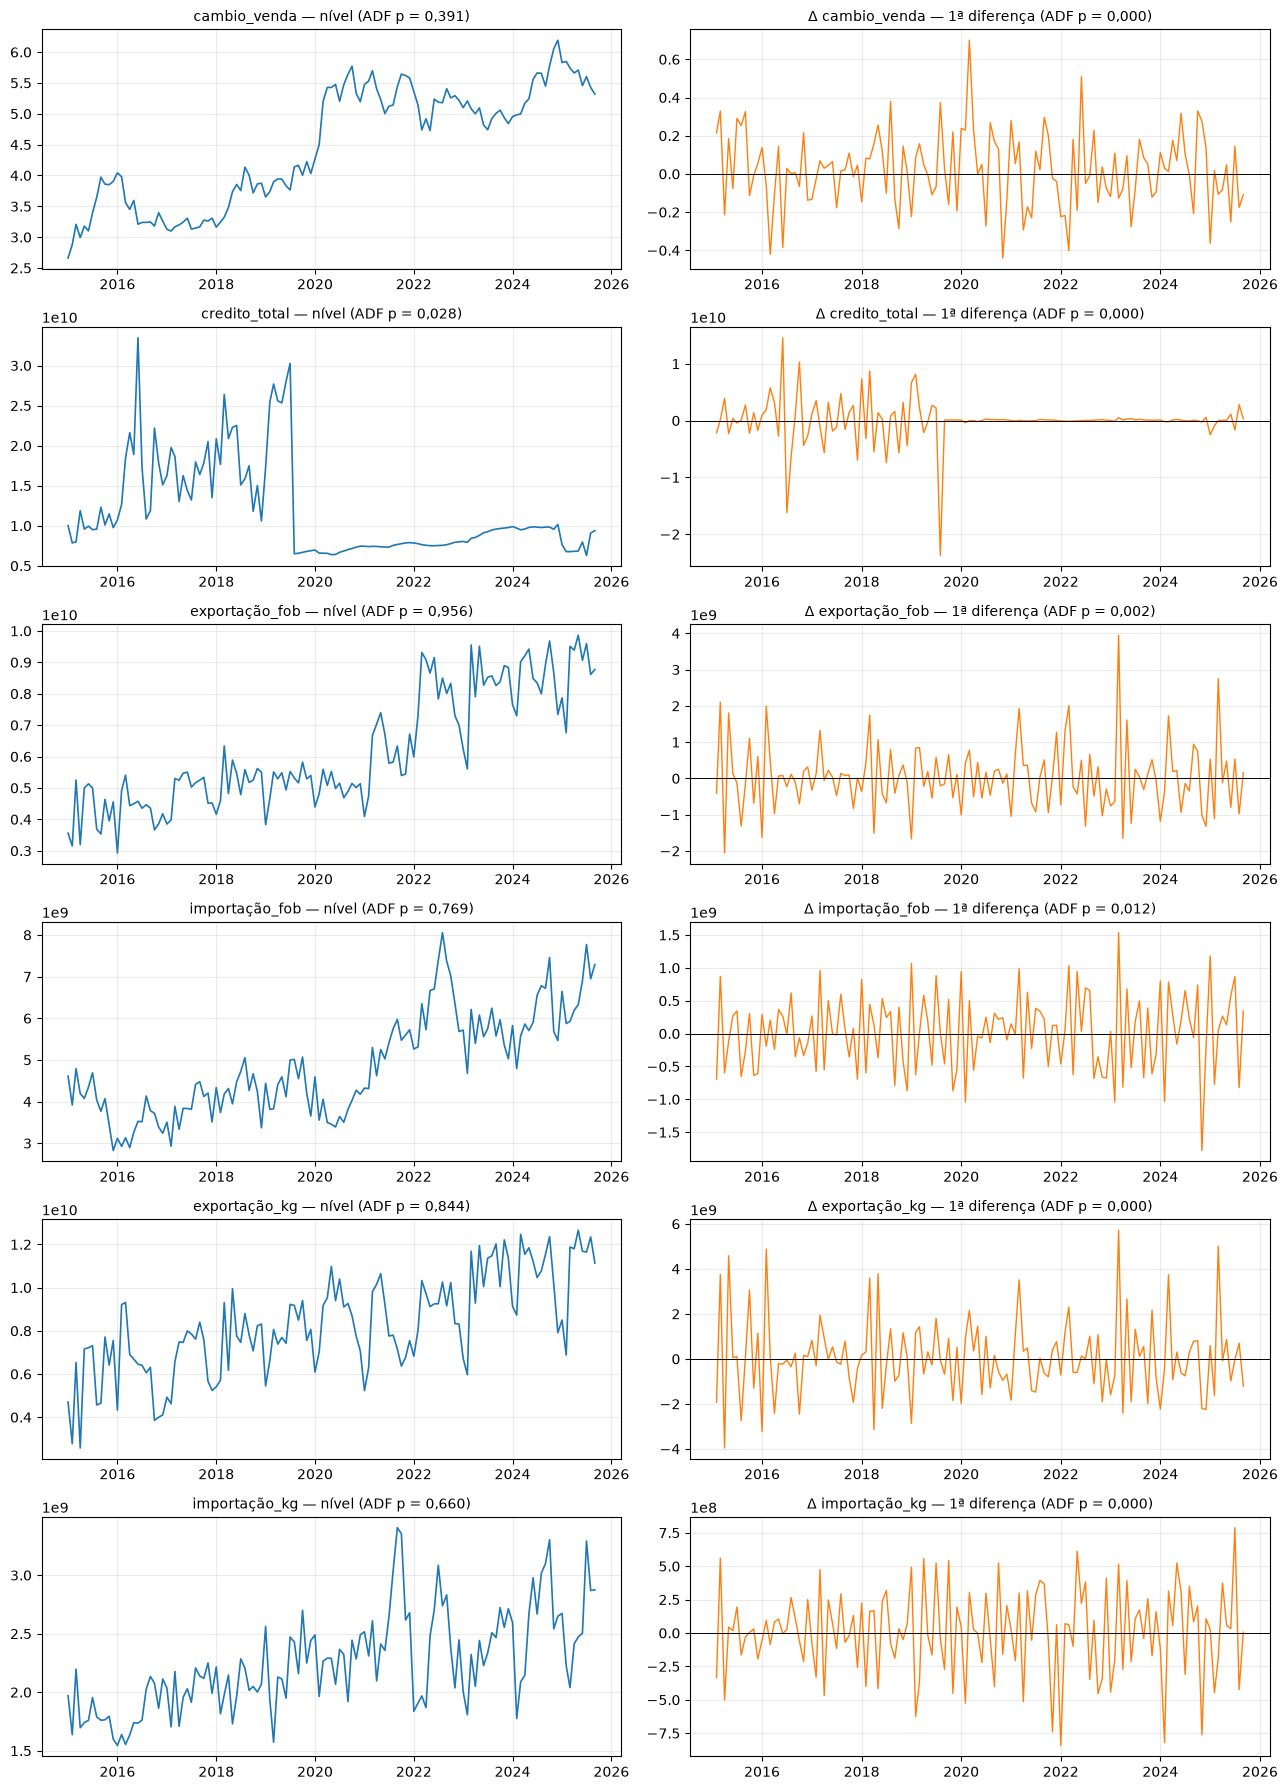

In [6]:
fig, axes = plt.subplots(len(series), 2, figsize=(13, 3 * len(series)))
for i, c in enumerate(series):
    axes[i, 0].plot(dados.index, dados[c], color='tab:blue', linewidth=1.2)
    axes[i, 0].set_title(f'{c} — nível (ADF p = {fmt(res_nivel[c]["p"], 3)})', fontsize=10)
    axes[i, 1].plot(dif.index, dif[c], color='tab:orange', linewidth=1.0)
    axes[i, 1].axhline(0, color='black', linewidth=0.7)
    axes[i, 1].set_title(f'Δ {c} — 1ª diferença (ADF p = {fmt(res_dif[c]["p"], 3)})', fontsize=10)
    for ax in axes[i]:
        ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Atenção especial: `credito_total` tem um degrau, não uma tendência

O ADF assume que a série se comporta de forma parecida ao longo do tempo; uma **quebra estrutural** (mudança abrupta de patamar) foge desse quadro. Perron (1989) mostrou que uma quebra desse tipo pode enganar o teste — em geral, fazendo-o *não* rejeitar raiz unitária mesmo quando a série é estacionária em torno da quebra. Por isso, um resultado do ADF em série com quebra dominante precisa ser lido com cuidado, qualquer que seja o veredito.

Abaixo, onde estão os maiores movimentos mensais de `credito_total` (medidos em desvios padrão da série diferenciada):

| mês | crédito no mês anterior (bi) | crédito no mês (bi) | variação | z da Δ |
|---|---|---|---|---|
| 2016-06 | 18,9 | 33,5 | 77% | 3,8 |
| 2016-07 | 33,5 | 17,3 | -48% | -4,2 |
| 2016-10 | 11,9 | 22,2 | 87% | 2,7 |
| 2019-08 | 30,3 | 6,5 | -79% | -6,1 |

O maior movimento mensal da série é em **2019-08**: |z| = 6,1. A média dos 12 meses antes é de 20,9 bi e a dos 12 meses a partir dele é de 6,6 bi.

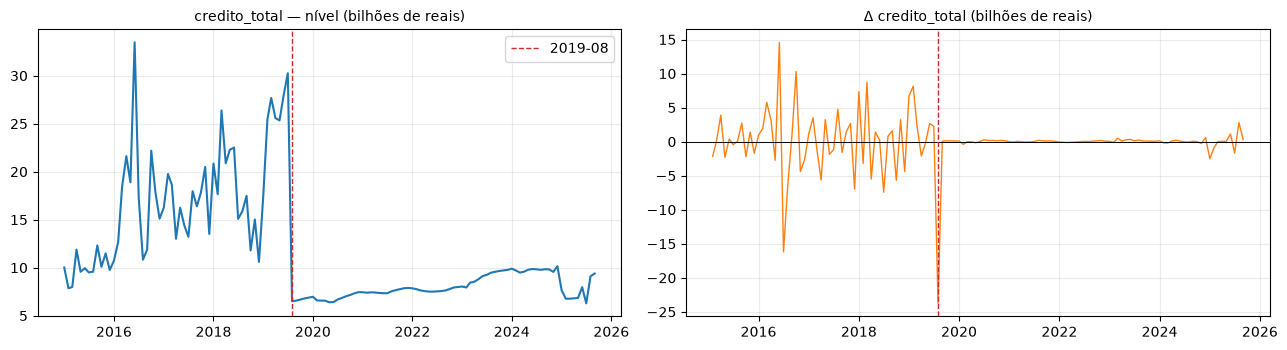

In [7]:
cred = dados['credito_total']
d_cred = cred.diff()
z = (d_cred - d_cred.mean()) / d_cred.std()
top = z.abs().sort_values(ascending=False).head(4).index.sort_values()

linhas = []
for dt in top:
    ant = cred.shift(1).loc[dt]
    linhas.append(f"| {dt.strftime('%Y-%m')} | {fmt(ant / 1e9, 1)} | {fmt(cred.loc[dt] / 1e9, 1)} | {fmt((cred.loc[dt] / ant - 1) * 100, 0)}% | {fmt(z.loc[dt], 1)} |")
display(Markdown('| mês | crédito no mês anterior (bi) | crédito no mês (bi) | variação | z da Δ |\n|---|---|---|---|---|\n' + '\n'.join(linhas)))

dt_max = z.abs().idxmax()
media_antes = cred[dt_max - pd.DateOffset(months=12): dt_max - pd.DateOffset(months=1)].mean() / 1e9
media_depois = cred[dt_max: dt_max + pd.DateOffset(months=11)].mean() / 1e9
display(Markdown(
    f"O maior movimento mensal da série é em **{dt_max.strftime('%Y-%m')}**: |z| = {fmt(abs(z.loc[dt_max]), 1)}. "
    f"A média dos 12 meses antes é de {fmt(media_antes, 1)} bi e a dos 12 meses a partir dele é de {fmt(media_depois, 1)} bi."
))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(cred.index, cred / 1e9, color='tab:blue')
axes[0].axvline(dt_max, color='tab:red', linestyle='--', linewidth=1, label=dt_max.strftime('%Y-%m'))
axes[0].set_title('credito_total — nível (bilhões de reais)', fontsize=10)
axes[0].legend()
axes[1].plot(d_cred.index, d_cred / 1e9, color='tab:orange', linewidth=1.0)
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].axvline(dt_max, color='tab:red', linestyle='--', linewidth=1)
axes[1].set_title('Δ credito_total (bilhões de reais)', fontsize=10)
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**O que isso muda na leitura dos passos anteriores:**

- No `04_temporal` a queda do crédito aparece descrita "em 2020", em comparação anual. A visão **mensal** acima mostra que o degrau está concentrado em **um único mês de 2019** — antes do início da pandemia — e que o patamar novo se mantém desde então; a média anual de 2020 só aparece baixa porque a de 2019 ainda embute os meses anteriores ao degrau. O câmbio, por outro lado, tem sua disparada em 2020 (visto no `04`).
- Isso importa para a pergunta "por que 2020?": no crédito, o ponto de virada precede 2020. **Causa em aberto** — o painel não permite dizer se é mudança real de crédito em Santos ou artefato de reporte/reclassificação no ESTBAN. Para separar as hipóteses seria preciso baixar o ESTBAN por banco em 2019 (como foi feito para 2025 no `03`). Fica registrado para a fase de contexto/pesquisa.
- Para o ADF, esse degrau único é o que domina a série diferenciada de `credito_total`: um ponto extremo isolado, o que a torna menos "bem-comportada" do que a das outras séries, mesmo que o teste aponte estacionariedade. O gráfico da Δ mostra ainda que **a variabilidade mensal antes do degrau é muito maior do que depois dele** (dois regimes de volatilidade), o que também viola a premissa de comportamento estável ao longo do tempo.

## 6. Sensibilidade: o veredito depende do critério de defasagens?

O número de defasagens do ADF foi escolhido por AIC, que tende a escolher mais termos; o BIC penaliza mais e tende a escolher menos. Se o veredito mudar entre os dois, ele é frágil e deve ser tratado com cautela.

In [8]:
linhas, mudou = [], []
for tipo, base in [('nível', dados), ('Δ', dif)]:
    for c in series:
        a = roda_adf(base[c], 'AIC')
        b = roda_adf(base[c], 'BIC')
        muda = a['ok'] != b['ok']
        if muda:
            mudou.append(f'{c} ({tipo})')
        linhas.append(f"| `{c}` | {tipo} | {fmt(a['p'], 4)} ({a['defas']}) | {fmt(b['p'], 4)} ({b['defas']}) | {'**muda**' if muda else 'igual'} |")

display(Markdown('| série | versão | p-valor AIC (defasagens) | p-valor BIC (defasagens) | veredito (5%) |\n|---|---|---|---|---|\n' + '\n'.join(linhas)))
if mudou:
    display(Markdown('**Vereditos que mudam entre AIC e BIC:** ' + ', '.join(mudou) + '. Tratar como frágeis.'))
else:
    display(Markdown('Nenhum veredito muda entre AIC e BIC.'))

C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(), regression='c', autolag=autolag)
C:\Users\Victo\AppData\Local\Temp\ipykernel_10792\3433859070.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, defas, nobs, crit, *_ = adfuller(serie.dropna(),

| série | versão | p-valor AIC (defasagens) | p-valor BIC (defasagens) | veredito (5%) |
|---|---|---|---|---|
| `cambio_venda` | nível | 0,3907 (0) | 0,3907 (0) | igual |
| `credito_total` | nível | 0,0282 (1) | 0,0026 (0) | igual |
| `exportação_fob` | nível | 0,9564 (13) | 0,9767 (11) | igual |
| `importação_fob` | nível | 0,7687 (12) | 0,6989 (1) | igual |
| `exportação_kg` | nível | 0,8439 (11) | 0,0001 (0) | **muda** |
| `importação_kg` | nível | 0,6597 (8) | 0,6597 (8) | igual |
| `cambio_venda` | Δ | 0,0000 (0) | 0,0000 (0) | igual |
| `credito_total` | Δ | 0,0000 (6) | 0,0000 (0) | igual |
| `exportação_fob` | Δ | 0,0025 (12) | 0,0000 (10) | igual |
| `importação_fob` | Δ | 0,0121 (11) | 0,0000 (0) | igual |
| `exportação_kg` | Δ | 0,0000 (10) | 0,0000 (0) | igual |
| `importação_kg` | Δ | 0,0000 (7) | 0,0000 (7) | igual |

**Vereditos que mudam entre AIC e BIC:** exportação_kg (nível). Tratar como frágeis.

## Resumo do passo 5

In [9]:
i1 = [c for c in series if not res_nivel[c]['ok'] and res_dif[c]['ok']]
i0 = [c for c in series if res_nivel[c]['ok']]
outras = [c for c in series if not res_nivel[c]['ok'] and not res_dif[c]['ok']]

texto = "- Testadas as 6 séries do `painel_credito` (2015-01 a 2025-09) com ADF (constante, defasagens por AIC), regra p < 0,05.\n"
texto += f"- **Precisam de 1 diferença (I(1))**: {', '.join('`'+c+'`' for c in i1) or 'nenhuma'}.\n"
texto += f"- **Estacionárias já no nível (I(0))**: {', '.join('`'+c+'`' for c in i0) or 'nenhuma'}.\n"
texto += f"- **Não estacionárias mesmo após 1 diferença**: {', '.join('`'+c+'`' for c in outras) or 'nenhuma'}.\n"
texto += ("- `credito_total` tem um degrau dominante (seção 5): o veredito do ADF nessa série deve ser lido com cautela, "
          "e a decisão de usá-la em nível ou em Δ nos passos seguintes fica **em aberto para o grupo**.\n")
texto += ("- Consequência para o passo 4: as correlações do `06` foram calculadas sobre níveis; "
          "as séries I(1) devem ser reavaliadas em primeira diferença antes de qualquer conclusão de relação entre elas.\n")
display(Markdown(texto))

- Testadas as 6 séries do `painel_credito` (2015-01 a 2025-09) com ADF (constante, defasagens por AIC), regra p < 0,05.
- **Precisam de 1 diferença (I(1))**: `cambio_venda`, `exportação_fob`, `importação_fob`, `exportação_kg`, `importação_kg`.
- **Estacionárias já no nível (I(0))**: `credito_total`.
- **Não estacionárias mesmo após 1 diferença**: nenhuma.
- `credito_total` tem um degrau dominante (seção 5): o veredito do ADF nessa série deve ser lido com cautela, e a decisão de usá-la em nível ou em Δ nos passos seguintes fica **em aberto para o grupo**.
- Consequência para o passo 4: as correlações do `06` foram calculadas sobre níveis; as séries I(1) devem ser reavaliadas em primeira diferença antes de qualquer conclusão de relação entre elas.


**Próximo passo (06 do roteiro):** decomposição em tendência, sazonalidade e resíduo (`08_decomposicao.ipynb`), pelo menos para `cambio_venda` e `exportação_fob`.

---

## Nota posterior (notebooks 10 e 11)

As duas pendências desta seção foram tratadas depois: o ESTBAN foi baixado por banco (`10_estban_por_banco_degrau_2019.ipynb`), que mostra que o degrau de agosto/2019 está concentrado no Bradesco (artefato de reporte provável, causa não documentada publicamente); e o crédito sem o Bradesco foi testado em logaritmo no `11_log_estacionariedade_correlacao.ipynb`, onde é **I(1)**, como as demais séries. O "I(0), com ressalva" do `credito_total` acima decorre, portanto, do degrau.